---
# Análise e Detecção de Pneumonia em Raios-X.

Modelo de Transfer Learning para Análise de Pneumonia.

---


## 📂 Upload do Dataset do Kaggle.

In [ ]:
# API Token Kaggle
!mkdir -p ~/.kaggle && echo KGAT_276c7e3d8cc56ec3286fb19d8e035119 > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

In [ ]:
# Importando os arquivos
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
!unzip -q chest-xray-pneumonia.zip -d dataset

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:24<00:00, 102MB/s]



## ⚙️ Contruindo o Modelo.

In [ ]:
# Bibliotecas necessárias
import tensorflow as tf
from tensorflow.keras import layers, models

import matplotlib.pyplot as plt
import numpy as np

In [ ]:
IMG_SHAPE = (224,224)
BATCH_SIZE = 32
DIRETORIO_DATA_TRAIN = "/content/dataset/chest_xray/train"

treinamento_data = tf.keras.utils.image_dataset_from_directory(
    DIRETORIO_DATA_TRAIN,
    validation_split=0.2,      # Separando 80% para treino
    subset="training",         # Pegando a parte de Treino
    seed=123,                  # Embaralhando as imagens
    image_size=(IMG_SHAPE),
    batch_size=BATCH_SIZE,
    label_mode='categorical'   #Converte pra One-Hot Encoding automático
  )

validacao_data = tf.keras.utils.image_dataset_from_directory(
    DIRETORIO_DATA_TRAIN,
    validation_split=0.2,      # Separando 20% para validação
    subset="validation",       # Pegando a parte de Validação
    seed=123,                  # Embaralhando as imagens
    image_size=(IMG_SHAPE),
    batch_size=BATCH_SIZE,
    label_mode='categorical'   #Converte pra One-Hot Encoding automático
  )

treinamento_data = treinamento_data.shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
validacao_data = validacao_data.prefetch(buffer_size=tf.data.AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.


In [ ]:
NUM_CLASSES = 2
IMG_SHAPE = (224,224,3)

# Construção do modelo:
def build_model_effcientnetv2s():
  inputs= layers.Input(shape=IMG_SHAPE)

  base_model = tf.keras.applications.EfficientNetV2S(
      include_top=False,
      weights="imagenet",
      input_tensor = inputs,
      include_preprocessing=True
  )

  base_model.trainable = False

  x = base_model.output
  x = layers.GlobalAveragePooling2D()(x)
  x = layers.BatchNormalization()(x)
  x = layers.Dense(256,activation='relu')(x)
  x = layers.Dropout(0.3)(x)
  outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

  model = models.Model(inputs, outputs, name="efficientNetV2S_CS")

  model.compile(
      optimizer= 'adam',
      loss= 'categorical_crossentropy',
      metrics=['accuracy']
  )

  return model

network = build_model_effcientnetv2s()  # Nome do modelo: "network"
network.summary()

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientNetV2S_CS"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        648 │ rescaling[0][0]   │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │         96 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      5,184 │ stem_activation[… │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         96 │ block1a_project_… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_add (Add)   │ (None, 112, 112,  │          0 │ block1a_project_… │
│                     │ 24)               │            │ stem_activation[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_co… │ (None, 112, 112,  │      5,184 │ block1a_add[0][0] │
│ (Conv2D)            │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_bn  │ (None, 112, 112,  │         96 │ block1b_project_… │
│ (BatchNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_project_ac… │ (None, 112, 112,  │          0 │ block1b_project_… │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_drop        │ (None, 112, 112,  │          0 │ block1b_project_… │
│ (Dropout)           │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1b_add (Add)   │ (None, 112, 112,  │          0 │ block1b_drop[0][… │
│                     │ 24)               │            │ block1a_add[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │     20,736 │ block1b_add[0][0] │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        384 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b

 Total params: 20,664,930 (78.83 MB)

 Trainable params: 331,010 (1.26 MB)

 Non-trainable params: 20,333,920 (77.57 MB)

In [ ]:
history = network.fit(
    treinamento_data,               # Input de treino
    validation_data=validacao_data, # Input de teste
    epochs=10                       # Quantas vezes ele vai estudar tudo
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 178s 672ms/step - accuracy: 0.9125 - loss: 0.2509 - val_accuracy: 0.9492 - val_loss: 0.1525
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - accuracy: 0.9463 - loss: 0.1508 - val_accuracy: 0.9578 - val_loss: 0.1139
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 44s 158ms/step - accuracy: 0.9482 - loss: 0.1275 - val_accuracy: 0.9674 - val_loss: 0.0844
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 125ms/step - accuracy: 0.9557 - loss: 0.1246 - val_accuracy: 0.9712 - val_loss: 0.0804
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 124ms/step - accuracy: 0.9573 - loss: 0.1022 - val_accuracy: 0.9732 - val_loss: 0.0719
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 86s 161ms/step - accuracy: 0.9626 - loss: 0.0945 - val_accuracy: 0.9569 - val_loss: 0.0921
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 125ms/step - accuracy: 0.9629 - loss: 0.0969 - val_accuracy: 0.9751 - val_loss: 0.0703
Epoch 8/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 42s 136ms/step - accuracy: 0.9662 - loss: 

## 📊 Análise dos Dados.

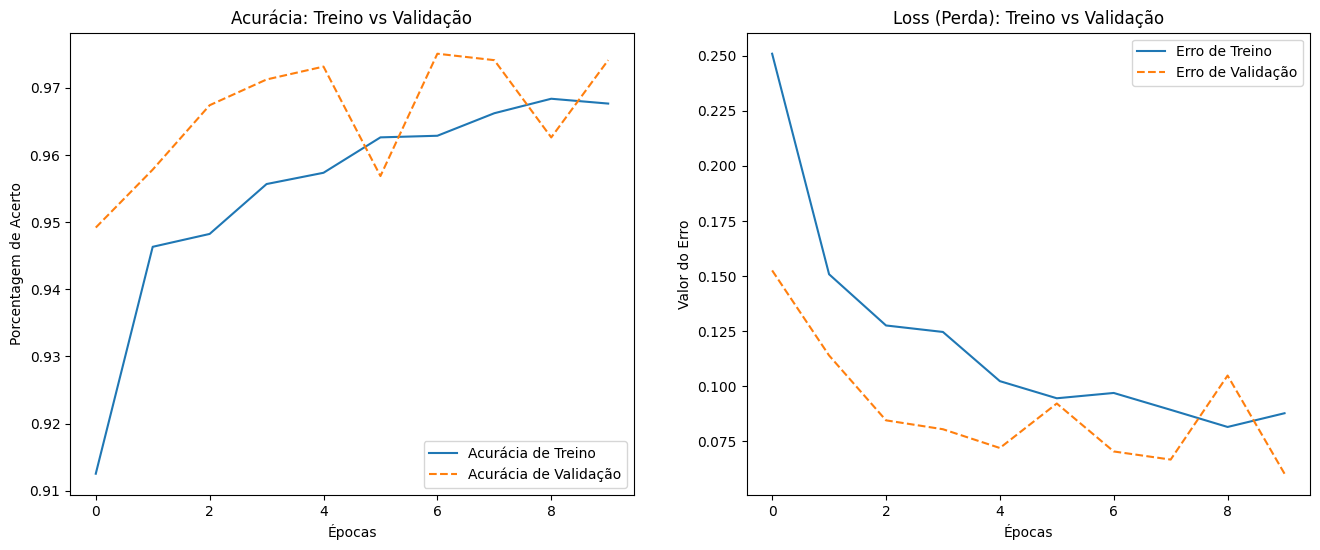

In [ ]:
acc = history.history['accuracy']           # Acurácia no Treino
val_acc = history.history['val_accuracy']   # Acurácia na Validação

loss = history.history['loss']              # Erro no Treino
val_loss = history.history['val_loss']      # Erro na Validação

epochs_range = range(len(acc))

plt.figure(figsize=(16, 6))

# GRÁFICO 1: ACURÁCIA
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Acurácia de Treino')
plt.plot(epochs_range, val_acc, label='Acurácia de Validação', linestyle='--')
plt.legend(loc='lower right')
plt.title('Acurácia: Treino vs Validação')
plt.xlabel('Épocas')
plt.ylabel('Porcentagem de Acerto')

# GRÁFICO 2: LOSS
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Erro de Treino')
plt.plot(epochs_range, val_loss, label='Erro de Validação', linestyle='--')
plt.legend(loc='upper right')
plt.title('Loss (Perda): Treino vs Validação')
plt.xlabel('Épocas')
plt.ylabel('Valor do Erro')

plt.show()

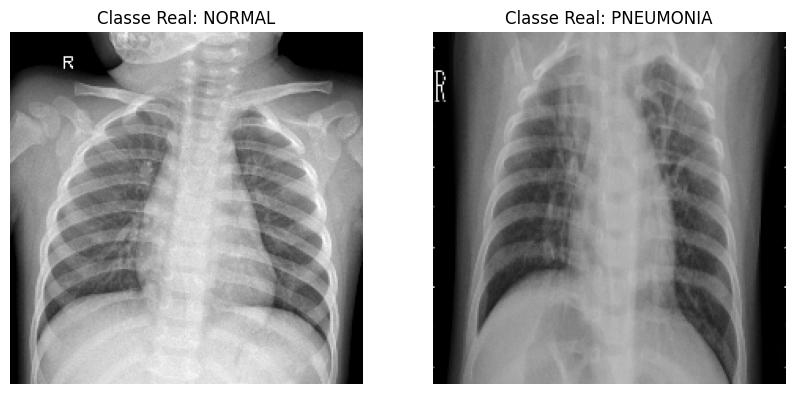

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Pegando os nomes das classes
class_names = ['NORMAL', 'PNEUMONIA']

plt.figure(figsize=(10, 5))

# Pega apenas o primeiro lote (batch) de imagens e labels
for images, labels in validacao_data.take(1):

    # Transforma as labels (one-hot) em índices (0 ou 1)
    labels_idx = np.argmax(labels.numpy(), axis=1)

    # Encontra o índice da primeira imagem Normal e da primeira com Pneumonia
    idx_normal = np.where(labels_idx == 0)[0][0]
    idx_pneumonia = np.where(labels_idx == 1)[0][0]

    # Plota a imagem Normal
    plt.subplot(1, 2, 1)
    plt.imshow(images[idx_normal].numpy().astype("uint8"))
    plt.title(f"Classe Real: {class_names[0]}")
    plt.axis("off")

    # Plota a imagem com Pneumonia
    plt.subplot(1, 2, 2)
    plt.imshow(images[idx_pneumonia].numpy().astype("uint8"))
    plt.title(f"Classe Real: {class_names[1]}")
    plt.axis("off")

plt.show()

Gerando predições e gabaritos sincronizados...


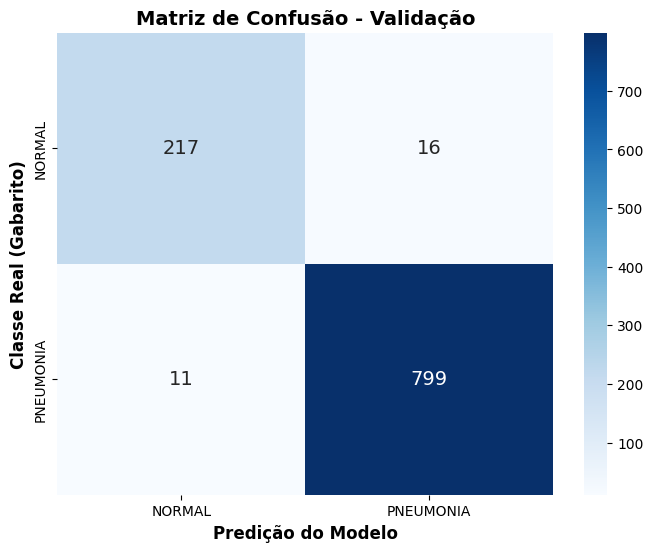

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

print("Gerando predições e gabaritos sincronizados...")
y_true = []
y_pred = []

# Extraindo imagens e gabaritos no mesmo exato momento para evitar dessincronização
for images, labels in validacao_data:
    # Prediz o lote atual
    preds = network.predict(images, verbose=0)

    # Armazena os resultados deste lote
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_pred = np.array(y_pred)
y_true = np.array(y_true)

# Gerando a Matriz de Confusão
cm = confusion_matrix(y_true, y_pred)

# Plotando
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'],
            annot_kws={"size": 14})

plt.xlabel('Predição do Modelo', fontsize=12, fontweight='bold')
plt.ylabel('Classe Real (Gabarito)', fontsize=12, fontweight='bold')
plt.title('Matriz de Confusão - Validação', fontsize=14, fontweight='bold')
plt.show()